In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
THETA_TRUE = 0.5       # Seuil cible inconnu f_theta
EPSILON = 0.1          # Paramètre d'erreur epsilon pour le PAC
DELTA = 0.05           # Paramètre de confiance delta (optionnel pour les graphiques)
NOISE_RATE = 0.1       # Taux de bruit pour la partie Agnostique
SAMPLE_SIZES = [5, 10, 20, 50, 100, 200]
NUM_REPETITIONS = 500  # Nombre de répétitions pour l'analyse PAC

Section 1 : Génération de données,nous définissons la fonction cible $f_{\theta}(x)$ et générons des échantillons d'entraînement uniformément répartis sur $\mathcal{X} = [0, 1]$

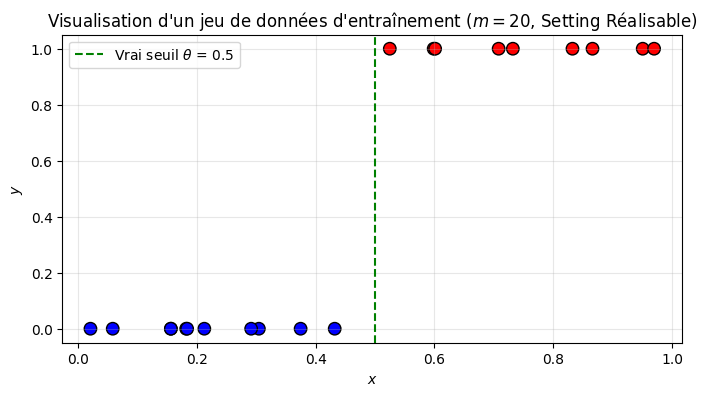

In [2]:
def target_function(x, theta):
    """Fonction cible f_theta(x)"""
    return (x > theta).astype(int)

def generate_data(m, theta, noise_rate=0.0, agnostic=False):
    """
    Génère m exemples uniformément dans [0, 1] avec ou sans bruit de label.
    """
    x = np.random.uniform(0, 1, m)
    y = target_function(x, theta)

    if agnostic and noise_rate > 0:
        #Inverser chaque étiquette indépendamment avec la probabilité noise_rate
        flip_mask = np.random.rand(m) < noise_rate
        y = np.logical_xor(y, flip_mask).astype(int)

    return x, y

#Visualisation pour m = 20
x_sample, y_sample = generate_data(20, THETA_TRUE)
plt.figure(figsize=(8, 4))
plt.scatter(x_sample, y_sample, c=y_sample, cmap='bwr', edgecolor='k', s=80)
plt.axvline(THETA_TRUE, color='green', linestyle='--', label=f'Vrai seuil $\\theta$ = {THETA_TRUE}')
plt.title("Visualisation d'un jeu de données d'entraînement ($m=20$, Setting Réalisable)")
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Pour un échantillon de taille $m$ faible (ex: $m=5$), les points peuvent être éloignés du vrai seuil $\theta$, ce qui rend l'apprentissage difficile,avec $m$ augmente, la couverture de l'espace $[0, 1]$ s'améliore

Section 2 : Implémentation de l'ERM, pour la classe d'hypothèses des classifieurs par seuil $h_{\tau}(x) = \mathbb{I}(x > \tau)$, l'algorithme ERM cherche le seuil $\tau$ qui minimise l'erreur empirique sur l'échantillon d'entraînement.Stratégie : Plutôt de tester une infinité de valeurs, il suffit de tester les points médians entre les valeurs triées de $x$, ainsi que les frontières extrêmes (par exemple $0$ et $1$)

In [3]:
class ThresholdERM:
    def __init__(self):
        self.best_threshold = None

    def fit(self, x, y):
        # Trier les points x et réordonner y en conséquence
        sorted_indices = np.argsort(x)
        x_sorted = x[sorted_indices]
        y_sorted = y[sorted_indices]

        # Candidats de seuils : milieu entre chaque point consécutif, plus les extrêmes
        candidates = [(x_sorted[i] + x_sorted[i+1]) / 2 for i in range(len(x_sorted) - 1)]
        candidates = [0.0] + candidates + [1.0]

        best_error = float('inf')
        best_tau = candidates[0]

        # Évaluer chaque seuil candidat
        for tau in candidates:
            preds = (x > tau).astype(int)
            # Erreur empirique : proportion d'erreurs de classification
            empirical_error = np.mean(preds != y)

            if empirical_error < best_error:
                best_error = empirical_error
                best_tau = tau

        self.best_threshold = best_tau
        return self.best_threshold

    def predict(self, x):
        return (x > self.best_threshold).astype(int)

Section 3 : Évaluation des performances, nous comparons l'erreur empirique (sur l'échantillon d'entraînement) et l'erreur vraie (calculée sur un grand jeu de test indépendant, par exemple $10000$ points)

In [4]:
# Génération d'un grand jeu de test indépendant
X_test, Y_test = generate_data(10000, THETA_TRUE)

print(f"{'m':<6} | {'Erreur Empirique':<18} | {'Erreur Vraie (True Error)'}")
print("-" * 50)

for m in SAMPLE_SIZES:
    x_train, y_train = generate_data(m, THETA_TRUE)

    # Entraînement ERM
    erm = ThresholdERM()
    erm.fit(x_train, y_train)

    # Calcul de l'erreur empirique
    train_preds = erm.predict(x_train)
    empirical_error = np.mean(train_preds != y_train)

    # Calcul de l'erreur vraie
    test_preds = erm.predict(X_test)
    true_error = np.mean(test_preds != Y_test)

    print(f"{m:<6} | {empirical_error:<18.4f} | {true_error:.4f}")

m      | Erreur Empirique   | Erreur Vraie (True Error)
--------------------------------------------------
5      | 0.0000             | 0.0423
10     | 0.0000             | 0.0986
20     | 0.0000             | 0.0074
50     | 0.0000             | 0.0004
100    | 0.0000             | 0.0065
200    | 0.0000             | 0.0023


 Dans le cadre réalisable, l'erreur empirique est souvent proche de $0$ (voire nulle si le seuil sépare parfaitement les données). L'erreur vraie diminue lorsque $m$ augmente, ce qui illustre la consistance de l'apprentissage

Section 4 : Vérification expérimentale de l'apprentissage PAC (PAC Learning), nous estimons la probabilité $\Pr(L(h) > \epsilon)$ en répétant l'expérience plusieurs fois pour chaque taille d'échantillon $m$

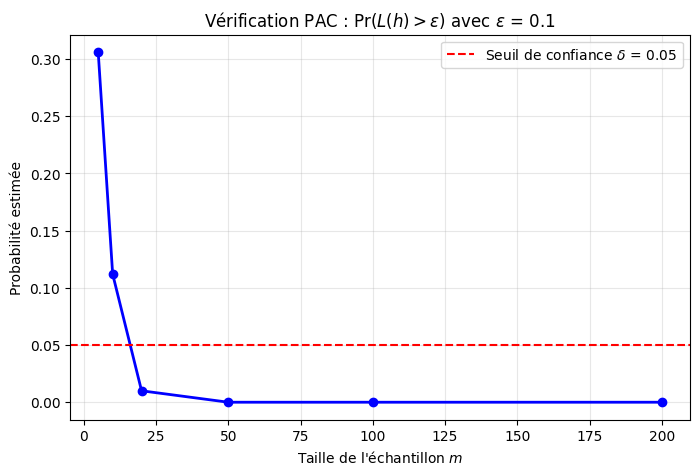

In [5]:
probabilities = []

for m in SAMPLE_SIZES:
    exceeded_count = 0

    for _ in range(NUM_REPETITIONS):
        x_train, y_train = generate_data(m, THETA_TRUE)

        erm = ThresholdERM()
        erm.fit(x_train, y_train)

        # Calcul de l'erreur vraie L(h)
        test_preds = erm.predict(X_test)
        true_error = np.mean(test_preds != Y_test)

        if true_error > EPSILON:
            exceeded_count += 1

    prob = exceeded_count / NUM_REPETITIONS
    probabilities.append(prob)

# Tracé de l'évolution de la probabilité en fonction de m
plt.figure(figsize=(8, 5))
plt.plot(SAMPLE_SIZES, probabilities, marker='o', linestyle='-', color='b', linewidth=2)
plt.axhline(DELTA, color='red', linestyle='--', label=f'Seuil de confiance $\\delta$ = {DELTA}')
plt.title(f"Vérification PAC : $\\Pr(L(h) > \\epsilon)$ avec $\\epsilon$ = {EPSILON}")
plt.xlabel("Taille de l'échantillon $m$")
plt.ylabel("Probabilité estimée")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

 On observe que la probabilité $\Pr(L(h) > \epsilon)$ décroît vers $0$ lorsque $m$ augmente. Cela valide empiriquement la PAC-généricité (Probably Approximately Correct) du cadre réalisable

Section 5 : Du PAC au PAC Agnostique,nous introduisons maintenant un bruit de label (taux $n = \text{NOISE\_RATE}$) et répétons les expériences pour comparer les deux cadres

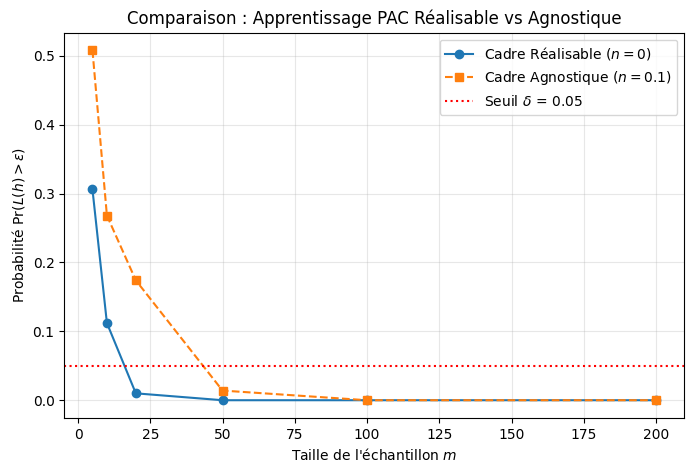

In [6]:
agnostic_probabilities = []

for m in SAMPLE_SIZES:
    exceeded_count = 0

    for _ in range(NUM_REPETITIONS):
        # Génération avec bruit (Agnostic)
        x_train, y_train = generate_data(m, THETA_TRUE, noise_rate=NOISE_RATE, agnostic=True)

        erm = ThresholdERM()
        erm.fit(x_train, y_train)

        # L'erreur vraie est évaluée par rapport à la fonction cible sans bruit
        test_preds = erm.predict(X_test)
        true_error = np.mean(test_preds != Y_test)

        if true_error > EPSILON:
            exceeded_count += 1

    prob = exceeded_count / NUM_REPETITIONS
    agnostic_probabilities.append(prob)

# Comparaison graphique Réalisable vs Agnostique
plt.figure(figsize=(8, 5))
plt.plot(SAMPLE_SIZES, probabilities, marker='o', linestyle='-', label='Cadre Réalisable ($n=0$)')
plt.plot(SAMPLE_SIZES, agnostic_probabilities, marker='s', linestyle='--', label=f'Cadre Agnostique ($n={NOISE_RATE}$)')
plt.axhline(DELTA, color='red', linestyle=':', label=f'Seuil $\\delta$ = {DELTA}')
plt.title("Comparaison : Apprentissage PAC Réalisable vs Agnostique")
plt.xlabel("Taille de l'échantillon $m$")
plt.ylabel("Probabilité $\\Pr(L(h) > \\epsilon)$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

La courbe du cadre réalisable montre que la probabilité $\Pr(L(h) > \epsilon)$ chute rapidement vers $0$ à mesure que la taille de l'échantillon $m$ augmente,le cadre réalisable suppose qu'il existe une fonction cible parfaite sans erreur, tandis que dans le cas agnostique (avec un taux de bruit de 10 %), la courbe est généralement plus haute et peut présenter un plateau, le cadre agnostique reconnaît la présence d'un bruit irréductible. L'ERM dans le cas agnostique ne cherche plus à atteindre une erreur nulle, mais à s'approcher de la meilleure performance possible au sein de la classe d'hypothèses ($\min_{h \in \mathcal{H}} L(h)$).

1/Can the empirical error still reach zero?

 Dans le cadre réalisable l'erreur empirique peut s'annuler si le modèle sépare parfaitement les données. Dans le cadre agnostique l'erreur empirique ne peut généralement plus atteindre zéro car les étiquettes bruitées créent des contradictions intrinsèques dans les données

2/Does increasing the number of training examples still improve the generalization performance?

 Oui l'augmentation de la taille de l'échantillon $m$ continue d'améliorer la performance de généralisation (l'erreur vraie diminue et se stabilise), car elle permet l'algorithme ERM d'estimer plus précisément le seuil malgré le bruit, contrairement au cas réalisable où l'erreur vraie tend vers 0, l'erreur de généralisation dans le cas agnostique se stabilise en deçà d'un plancher minimum incompressible (lié au risque de Bayes et au taux de bruit $n$).

3/ How do your observations relate to the PAC and Agnostic PAC learning frameworks
introduced during the lectures?

Cadre PAC standard: Suppose qu'il existe un classifieur parfait ($L_{\mathcal{D}}(h) = 0$). L'algorithme garantit une erreur $< \epsilon$ avec une forte confiance, ce qui correspond à notre courbe sans bruit où l'erreur tend vers zéro
Cadre Agnostic PAC: Relâche cette hypothèse car le bruit empêche une erreur nulle. L'objectif n'est plus d'atteindre zéro, mais de rivaliser avec la meilleure hypothèse possible de la classe ($\min L_{\mathcal{D}}(h') + \epsilon$), ce qui explique le palier observé dans notre simulation bruitée